In [ ]:
# Author: Polina Gridiaeva
# Department of Computational Physics,
# Faculty of Physics, Saint Petersburg State University
# Date: June 2025

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import scipy as sp
import seaborn as sns
import rarfile
from scipy.stats import norm
import pandas as pd

In [2]:
Z = 79
A = 197
C = 29.9792 # (cm/ns)
COMP_EN = 11.006
Rel_Err = 0.05 #Relative error (instead of eps = 1e-8)

In [3]:
# define detector geometry

D1 = 5      #inner hole (cm)
D2 = 50     #outer hole (cm)
num_rings = 6  #number of radial rings
num_sectors = 10  #number of sectors(angular divisions)
R1 = D1/2       #inner radius (cm)
R2 = D2/2       #outer radius (cm)
z_detector1 = -400  #distance from the collision point (cm) - 1st detector
z_detector2 = 400   #distance from the collision point (cm) - 2st detector
z_detector = z_detector1 = z_detector2

# define ring and sector boundaries

ring_edges = np.linspace(R1, R2, num_rings + 1)
sector_edges = np.linspace(0, 2 * math.pi, num_sectors + 1)
print(ring_edges)
print(sector_edges)

[ 2.5   6.25 10.   13.75 17.5  21.25 25.  ]
[0.         0.62831853 1.25663706 1.88495559 2.51327412 3.14159265
 3.76991118 4.39822972 5.02654825 5.65486678 6.28318531]


In [4]:
# particle trajectory simulation


# a function that projects the trajectory of a particle
# and return (x,y) and time of flight (tof)

def project_to_detector(p_x, p_y, p_z, Mass, Z_detector):
    
    if p_z == 0:
        print("will never cross")       # particle will never touch the detector

    time_parameter = Z_detector / p_z
    x_hit = time_parameter * p_x
    y_hit = time_parameter * p_y
    C = 29.9792 # (cm/ns)
    p = np.sqrt(p_x**2 + p_y**2 + p_z**2)
    energy = np.sqrt(p**2 + Mass**2)
    velocity = (p / energy) * C      # particle velocity in (cm/ns)
    tof = abs(Z_detector) / velocity # time of flight in nanoseconds
    t0 = abs(Z_detector) / C # our shift in time -> the time it takes for the light to reach the detector
    #print('Time = ',tof,'s; shift = ', t0, 's.')
    Tof = 1 / (tof - t0)
    return x_hit, y_hit, Tof

In [5]:
# particle trajectory simulation
# next step - define the pad ; (x,y) - its x_hit and y_hit 
# try to determine which pad particle hits. pad = (ring; sector)

def find_pad(x, y):
    # conversion to polar coordinates
    r = np.sqrt(x**2 + y**2)
    fi = np.arctan2(y, x)  #returns the angle between [-pi; pi]

    # fi : [0; 2pi]
    if fi < 0:
        fi += 2 * np.pi

    ring_num = np.digitize([r], ring_edges) - 1
    sector_num = np.digitize([fi], sector_edges) 
    # checking if the particle hit the detector
    if ring_num[0] <= 0 or ring_num[0] > num_rings:
        return None
    else:
        return [ring_num[0].item(), sector_num[0].item()]

In [ ]:
def create_feature_vector(filtered_pads_tof, pz_values, max_particles = 120):

    # create a table filed with zeros
    feature_matrix = np.zeros((3, max_particles))
    #print(feature_matrix)
    # pads and tof extraction
    pads = [pad for pad, _ in filtered_pads_tof] # pads extraction
    tof_s = [tof for _, tof in filtered_pads_tof] # tof extraction
    # number of particles restriction
    num_particles = min(len(tof_s), max_particles)
    #print(num_particles)
    for num in range(num_particles):

        # tof, ring, sector, pz extraction
        tof = tof_s[num]
        #ring, sector = pads[num]
        pz = pz_values[num]

        # detector def 
        if pz > 0:
            detector_id = 1
        else:
            detector_id = 2
        
        # encode pad like 1 number
        
        pad_encoded = int(''.join(map(str, pads[num])))
        #print(pad_encoded)
       
            # make a vector 
        feature_matrix[0][num] = tof
        feature_matrix[1][num] = pad_encoded
        feature_matrix[2][num] = detector_id
    feature_vector = feature_matrix.T.flatten()
    
    return feature_vector

In [7]:
def filter_min_tof(pads, tof_s):

        # create a dictionary to store the min tof for each pad: key -> pad; value -> tof
    pad_to_tof = {}
        # iterate throught all pads and their tof values
    zipped = zip(pads, tof_s)
        #print(zipped)
    for i_pad, j_tof in zipped:

            pad_tuple = tuple(i_pad)    # convert list -> tuple, because dict use cant use lists in keys
            # if pad is already in the dict => update if new tof is smaller 
            if pad_tuple in pad_to_tof:
                pad_to_tof[pad_tuple] = min(pad_to_tof[pad_tuple], j_tof) 
            else:
                pad_to_tof[pad_tuple] = j_tof # else add new pad to dict with its tof


        # сonvert the dict into a list of lists 
    filtered_pads_tof = [[list(pad), tof] for pad, tof in pad_to_tof.items()]
    

    return filtered_pads_tof

In [19]:
# приводим X и y к диапазоону значений [0, 1] - train our model
from sklearn.preprocessing import MinMaxScaler
def normalize(X_train, X_test, y_train, y_test):

    X_scaler = MinMaxScaler()
    y_scaler = MinMaxScaler()

    X_train_scaled = X_scaler.fit_transform(X_train)
    y_train_scaled = y_scaler.fit_transform(np.array(y_train).reshape(-1, 1))

    X_test_scaled = X_scaler.transform(X_test)
    y_test_scaled = y_scaler.transform(np.array(y_test).reshape(-1, 1))

    return X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled, X_scaler, y_scaler

In [17]:
# приводим y к обычным значениям обратно - make pictures and count RMSE
def denormalize(y_scaled, y_scaler):

    y_before_scaling = y_scaler.inverse_transform(y_scaled)

    return y_before_scaling

In [10]:
for i in range(1, 201):  
    filename = f"data_{i:02d}.dat"  
    print(filename)

data_01.dat
data_02.dat
data_03.dat
data_04.dat
data_05.dat
data_06.dat
data_07.dat
data_08.dat
data_09.dat
data_10.dat
data_11.dat
data_12.dat
data_13.dat
data_14.dat
data_15.dat
data_16.dat
data_17.dat
data_18.dat
data_19.dat
data_20.dat
data_21.dat
data_22.dat
data_23.dat
data_24.dat
data_25.dat
data_26.dat
data_27.dat
data_28.dat
data_29.dat
data_30.dat
data_31.dat
data_32.dat
data_33.dat
data_34.dat
data_35.dat
data_36.dat
data_37.dat
data_38.dat
data_39.dat
data_40.dat
data_41.dat
data_42.dat
data_43.dat
data_44.dat
data_45.dat
data_46.dat
data_47.dat
data_48.dat
data_49.dat
data_50.dat
data_51.dat
data_52.dat
data_53.dat
data_54.dat
data_55.dat
data_56.dat
data_57.dat
data_58.dat
data_59.dat
data_60.dat
data_61.dat
data_62.dat
data_63.dat
data_64.dat
data_65.dat
data_66.dat
data_67.dat
data_68.dat
data_69.dat
data_70.dat
data_71.dat
data_72.dat
data_73.dat
data_74.dat
data_75.dat
data_76.dat
data_77.dat
data_78.dat
data_79.dat
data_80.dat
data_81.dat
data_82.dat
data_83.dat
data

In [11]:
all_features = [] # final vector with all features (independent)
all_energies = [] # final vector with energy per collision (dependent)

for i in range(1, 101):  
    file_index = f"D:\\200k\\data_{i:d}.dat"
    
    with open(file_index, 'r') as f:
        lines1 = f.readlines()

    i = 5
    #b_need = []
    pz_values = []
    #energies = []
    #all_events_pads = []
    #all_events_tof_s = []
    #pz_all = []
    while i < len(lines1):
        l = lines1[i]
        n = [float(num) for num in l.split()]
        n_part = int(n[1])
        #b = n[2]
        #bx = n[3]
        #by = n[4]
        #print(f' n = {n_part}')
        i += 1
        prev_i = i
        tot_en = 0  # полная энергия всех нуклонов
        all_pads = []
        tof_s = []
        pads = []
        active_nucleons = 0 # число нуклонов, участвующих в столкновении
        
        while i < prev_i + n_part:
            l = lines1[i]
            params = [float(num) for num in l.split()]
            #type = int(params[4])
            mass = params[10]
            charge = params[0]
            px = abs(params[5])
            py = abs(params[6])
            pz = abs(params[7])
            condition1 = math.isclose(px, pz, abs_tol=0.9 * pz)
            condition2 = math.isclose(py, pz, abs_tol=0.9 * pz)
            #(type == 2212 or type == 2112)
            if (mass >= 9.38200E-01) and (not condition1) and (not condition2):
                energy_csm = (params[5]**2 + params[6]**2 + params[7]**2 + mass**2)**(1/2)

                #print(energy_csm, '  ', COMP_EN)
                if (math.isclose(energy_csm, COMP_EN, rel_tol = COMP_EN * Rel_Err)):
                    #print(b, energy_csm)
                    t = 0
                    #print(l)
                else:
                    active_nucleons += 1
                    tot_en += energy_csm
                    if charge != 0:
                        # pz_values.append(pz)
                        x, y, t = project_to_detector(px, py, pz, mass, z_detector)
                        #print(t)
                        pad = find_pad(x, y)
                        all_pads.append(pad)
                        # deleting [-100;100] - if particles didnt hit the detector
                        pads = [pad for pad in all_pads if pad is not None]
                        pz_values.append(pz)
                        tof_s.append(t.item())
                        #print(f'charge: {charge} and i = {i}')
            
            i += 1
# 0 // 2 = 0 and 1 // 2 = 0

            if active_nucleons >= 2:
                n_pairs = active_nucleons // 2
                energy_per_pair = tot_en / n_pairs
            else:
                energy_per_pair = 0
            
                

        all_energies.append(energy_per_pair)

        filtered = filter_min_tof(pads, tof_s)
        feature_vec = create_feature_vector(filtered, pz_values)

        all_features.append(feature_vec)
        #all_events_pads.append(pads)
        #all_events_tof_s.append(tof_s)
        #pz_all.append(pz_values)

In [ ]:

all_features = [] # final vector with all features (independent)
all_energies = [] # final vector with energy per collision (dependent)


for i in range(1, 101):  
    file_index = f"D:\\200k\\data_{i:d}.dat"
    
    with open(file_index, 'r') as f:
        lines1 = f.readlines()

    i = 5
    #b_need = []
    pz_values = []
    #energies = []
    #all_events_pads = []
    #all_events_tof_s = []
    #pz_all = []
    while i < len(lines1):
        l = lines1[i]
        n = [float(num) for num in l.split()]
        n_part = int(n[1])
        #b = n[2]
        #bx = n[3]
        #by = n[4]
        #print(f' n = {n_part}')
        i += 1
        prev_i = i
        tot_en = 0  # полная энергия всех нуклонов
        all_pads = []
        tof_s = []
        pads = []
        
        while i < prev_i + n_part:
            l = lines1[i]
            params = [float(num) for num in l.split()]
            #type = int(params[4])
            mass = params[10]
            charge = params[0]
            px = abs(params[5])
            py = abs(params[6])
            pz = abs(params[7])
            condition1 = math.isclose(px, pz, abs_tol=0.9 * pz)
            condition2 = math.isclose(py, pz, abs_tol=0.9 * pz)
            #(type == 2212 or type == 2112)
            if charge != 0:
                if (mass >= 9.38200E-01) and (not condition1) and (not condition2):
                    energy_csm = (params[5]**2 + params[6]**2 + params[7]**2 + C**2*mass**2)**(1/2)

                    #print(energy_csm, '  ', COMP_EN) # rel_tol = COMP_EN * Rel_Err
                    if (math.isclose(energy_csm, COMP_EN, abs_tol = Rel_Err * COMP_EN)):
                        #print(b, energy_csm)
                        t = 0
                        #print(l)
                    else:
                        tot_en += energy_csm
                        # pz_values.append(pz)
                        x, y, t = project_to_detector(px, py, pz, mass, z_detector)
                        #print(t)
                        pad = find_pad(x, y)
                        all_pads.append(pad)
                        # deleting [-100;100] - if particles didnt hit the detector
                        pads = [pad for pad in all_pads if pad is not None]
                        pz_values.append(pz)
                        tof_s.append(t.item())
                        #print(f'charge: {charge} and i = {i}')
            
            i += 1
            
        all_energies.append(tot_en)
        filtered = filter_min_tof(pads, tof_s)
        
        feature_vec = create_feature_vector(filtered, pz_values)
        all_features.append(feature_vec)
        #all_events_pads.append(pads)
        #all_events_tof_s.append(tof_s)
        #pz_all.append(pz_values)

In [12]:

print(torch.tensor(all_features).shape)


torch.Size([200000, 360])


C:\Users\ПК\AppData\Local\Temp\ipykernel_14788\3210518613.py:1: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:257.)
  print(torch.tensor(all_features).shape)


In [13]:
with open('all_features.txt', 'w') as f:
    for i in range(len(all_features)):
        f.write(str(all_features[i]))

In [14]:
feature_matrixx = np.ones((len(all_features), 360))

for i in range(len(all_features)):
    feature_matrixx[i][:] = all_features[i]

print(feature_matrixx.shape)

(200000, 360)


In [20]:
# makes train and test sets

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(feature_matrixx, all_energies, test_size=0.2, random_state=42)

# Normalization

X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled, X_scaler, y_scaler = normalize(X_train, X_test, y_train, y_test)

In [21]:
# step 2 - create our own DataSet class
# features - list of feature vectors, one for each event <=> dim = [N, 3*120] N - number of events
# energies - list of energies in every event <=> dim = N

class QGSMCollisionDataset(Dataset):
    def __init__(self, all_features, all_energies):
        self.X = torch.tensor(all_features, dtype = torch.float32)
        self.y = torch.tensor(all_energies, dtype = torch.float32).unsqueeze(1) # [N, 1]
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [22]:
# step 3 - neural network architecture

class EnergyRegressor(nn.Module):
    def __init__(self):
        super(EnergyRegressor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(360, 128),
            nn.SiLU(),
            nn.Linear(128, 64),
            nn.SiLU(),
            nn.Linear(64, 32),
            nn.SiLU(),
            nn.Linear(32, 16),
            nn.SiLU(),
            nn.Linear(16, 1)
        )

        
    def forward(self, x):
        f_out = self.net(x)
        return f_out

In [21]:
class EnergyRegressor(nn.Module):
    def __init__(self):
        super(EnergyRegressor, self).__init__()
        
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=8, kernel_size=(6, 3)),  
            nn.ReLU()
        )
        
        
        self.fc = nn.Sequential(
            nn.Flatten(),  
            nn.Linear(8 * 115 * 1, 128),  
            nn.SiLU(),
            nn.Linear(128, 64),
            nn.SiLU(),
            nn.Linear(64, 32),
            nn.SiLU(),
            nn.Linear(32, 16),
            nn.SiLU(),
            nn.Linear(16, 1)  
        )

    def forward(self, x):
        x = x.view(-1, 1, 120, 3)  
        x = self.conv(x)
        x = self.fc(x)
        return x

In [22]:
        # Вход: (120, 3) → (115, 1) по высоте (120 - 6 + 1 = 115), ширина (3 - 3 + 1 = 1)
        # Выход Conv2d: [batch, 16, 115, 1]

In [24]:
# step 4 - training our model 

def train_model(X_train, y_train, X_test, y_test, epochs = 1500, batch_size = 3000, learning_rate = 0.001, patience = 100):

    dataset = QGSMCollisionDataset(X_train, y_train)
    loader = DataLoader(dataset, batch_size = batch_size, shuffle = True) # split on batches and mix them
    X_test = torch.tensor(X_test, dtype=torch.float32)
    y_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

    model = EnergyRegressor() 
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr = learning_rate, weight_decay=1e-5)

    train_losses = []
    test_losses = []
    
    best_val_loss = float('inf')    # least validation error
    best_model_state = None # best weight models
    patience_counter = 0    # add one if the error does not decrease
    
    print("Minimum:", torch.min(torch.tensor(y_train, dtype=torch.float32)).item())
    print("Maximum:", torch.max(torch.tensor(y_train, dtype=torch.float32)).item())
    print("Mean:", torch.mean(torch.tensor(y_train, dtype=torch.float32)).item())
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for batch_X, batch_y in loader:
            #print('X.shape = ',batch_X.shape, "Y.shape = ", batch_y.shape)
            optimizer.zero_grad()       # reset gradients -> 0
            outputs = model(batch_X)    # make a prediction
            loss = criterion(outputs, batch_y)  # calculate out loss
            loss.backward()     # calculate gradients
            optimizer.step()    # update weights
            running_loss += loss.item()

        avg_train_loss = running_loss / len(loader) # average loss for 1 epoch
        train_losses.append(avg_train_loss) # for visualization

        # error estimation on the test sample
        model.eval()
        with torch.no_grad():
            test_preds = model(X_test)
            test_loss = criterion(test_preds, y_test).item()
        test_losses.append(test_loss)
        
        # early stopping
        if test_loss < best_val_loss:
            best_val_loss = test_loss
            best_model_state = model.state_dict()
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"early stopping triggered at epoch {epoch}")
                break
        
        if epoch % 100 == 0:
            print(f"running loss: {running_loss}", f"epoch: {epoch}")
    
    model.load_state_dict(best_model_state)
    
    # visualization
    plt.figure(figsize=(10, 5))
    plt.loglog(train_losses, color = 'red', label = 'Loss(TRAIN)')
    plt.loglog(test_losses, color = 'blue', label = 'Loss(TEST)')
    plt.title('Train VS Test Loss Evaluation')
    plt.xlabel('epoch')
    plt.ylabel('MSE - our loss')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

            
    return model

In [ ]:
r = train_model(X_train, y_train, X_test, y_test)
print(r)

Minimum: 0.0
Maximum: 1.0
Mean: 0.11354392021894455


c:\Users\ПК\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\loss.py:610: UserWarning: Using a target size (torch.Size([3000, 1, 1])) that is different to the input size (torch.Size([3000, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
c:\Users\ПК\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\loss.py:610: UserWarning: Using a target size (torch.Size([1000, 1, 1])) that is different to the input size (torch.Size([1000, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
c:\Users\ПК\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\loss.py:610: UserWarning: Using a target size (torch.Size([40000, 1, 1])) that is different to the input size (torch.Size([40000, 1])). This wi

running loss: 3.001113124191761 epoch: 0


In [ ]:
# predicted and true energy values with Normalization

X_test_sc = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_sc = torch.tensor(y_test_scaled, dtype=torch.float32).unsqueeze(1)

r.eval()
with torch.no_grad():
    y_true_scaled = y_test_sc.squeeze().numpy()
    y_pred_scaled = r(X_test_sc).squeeze().detach().numpy()

y_true = denormalize(y_true_scaled, y_scaler)
y_test = denormalize(y_test_scaled, y_scaler)

In [ ]:
# predicted and true energy values
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

r.eval()
with torch.no_grad():
    y_true = y_test.squeeze().numpy()
    y_pred = r(X_test).squeeze().detach().numpy()

In [25]:
min_energy = y_true.min()
max_energy = y_true.max()
step = (max_energy - min_energy) / 3
d1 = min_energy + step
d2 = d1 + step
d3 = d2 + step
print(f'Step: {step}')
print(f'Min Energy: {min_energy}')
print(f'Max Energy: {max_energy}')
print(f'd1 = {d1}')
print(f'd2 = {d2}')
print(f'd3 = {d3}')

Step: 693.068115234375
Min Energy: 88.53295135498047
Max Energy: 2167.7373046875
d1 = 781.60107421875
d2 = 1474.669189453125
d3 = 2167.7373046875


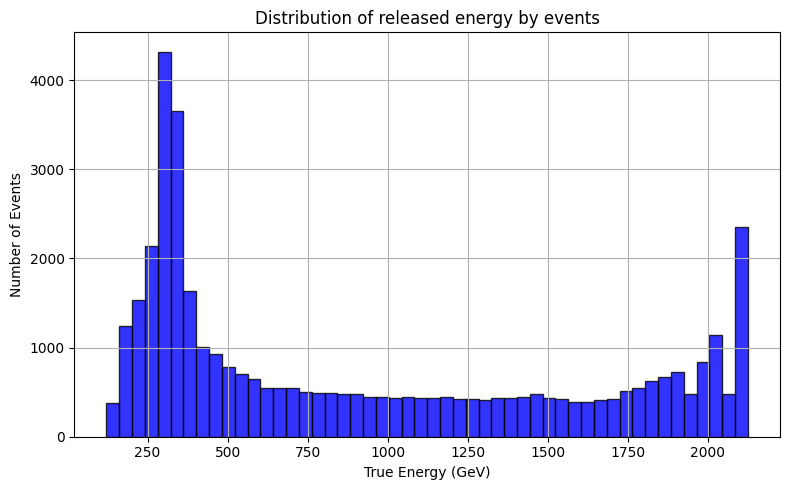

In [26]:
plt.figure(figsize=(8, 5))

# constructing the distribution of true energy values
plt.hist(y_pred, bins=50, color='blue', edgecolor='black', alpha=0.8)
plt.title("Distribution of released energy by events")
plt.xlabel("True Energy (GeV)")
plt.ylabel("Number of Events")
plt.grid(True)
plt.tight_layout()
plt.show()

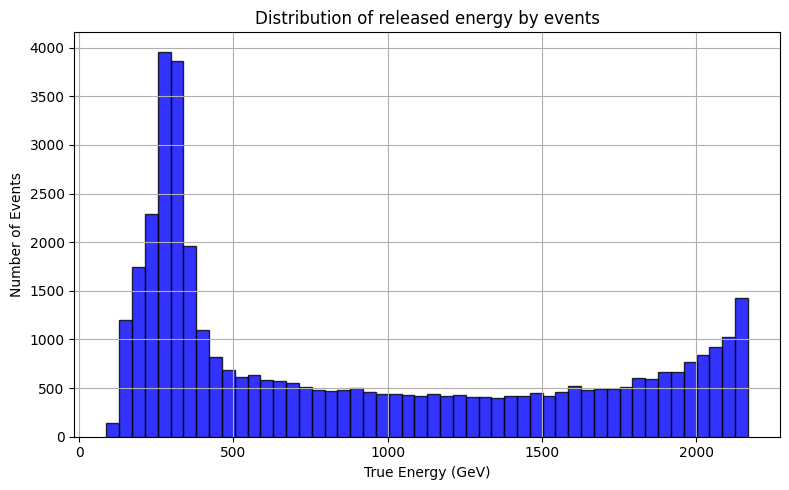

In [27]:
plt.figure(figsize=(8, 5))

# constructing the distribution of true energy values
plt.hist(y_true, bins=50, color='blue', edgecolor='black', alpha=0.8)
plt.title("Distribution of released energy by events")
plt.xlabel("True Energy (GeV)")
plt.ylabel("Number of Events")
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
from sklearn.metrics import mean_squared_error
# metric intro on the test set
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
print(f"RMSE: {rmse:.5f} GeV")

RMSE: 153.96123 GeV


In [ ]:
#hist func

def plot_error_hist(errors, label):
    #errors_np = errors.numpy()
    mu = np.mean(errors)
    sigma = np.std(errors)
    x = np.linspace(min(errors), max(errors), 1000)
    gaussian_curve = norm.pdf(x, mu, sigma)
    plt.figure(figsize=(8, 5))
    plt.hist(errors, bins=100, density=True, color='lightblue', edgecolor='black', alpha=0.7, label='Errors')

    
    plt.plot(x, gaussian_curve, color='darkblue', linewidth=2.5, label='Gaussian approximation')
    plt.axvline(0, color='red', linestyle='--', label='Zero error')
    plt.title(f"Error histogram with Gaussian approximation — {label} energy", fontsize=14)
    plt.xlabel("prediction error (GeV)", fontsize=12)
    plt.ylabel("probability density", fontsize=12)
    plt.legend()
    plt.grid(True) 
    plt.tight_layout()
    plt.show()
    #import pandas as pd
    
    #counts, bin_edges = np.histogram(errors, bins=100, density=True)
    #hist_data = pd.DataFrame({
    #    'Bin_Center': (bin_edges[:-1] + bin_edges[1:]) / 2,  # Центры интервалов
    #    'Counts': counts
    #})

    
    hist_data.to_csv('histogram_data.csv', index=False)
    
    #print("bin edges x:", bin_edges)
    #print("counts y:", counts)

c:\Users\ПК\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(


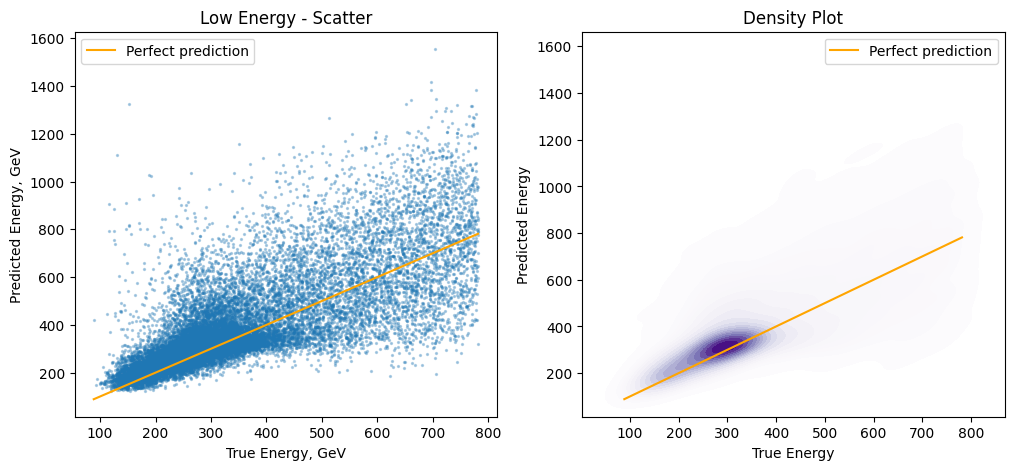

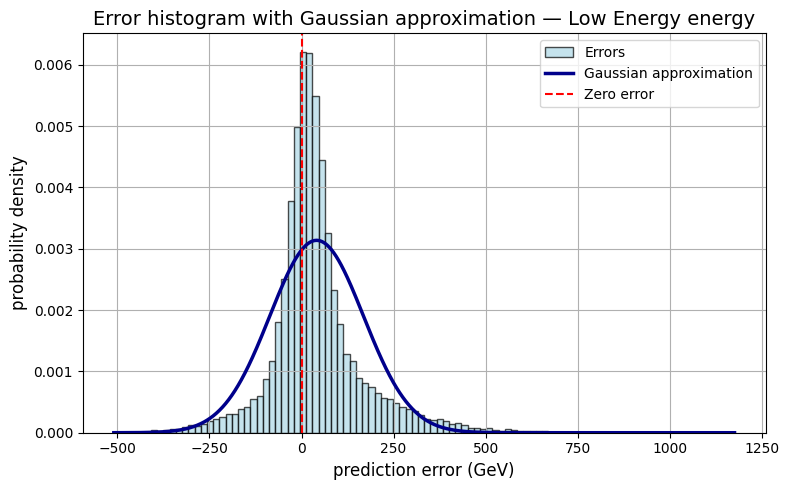

c:\Users\ПК\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(


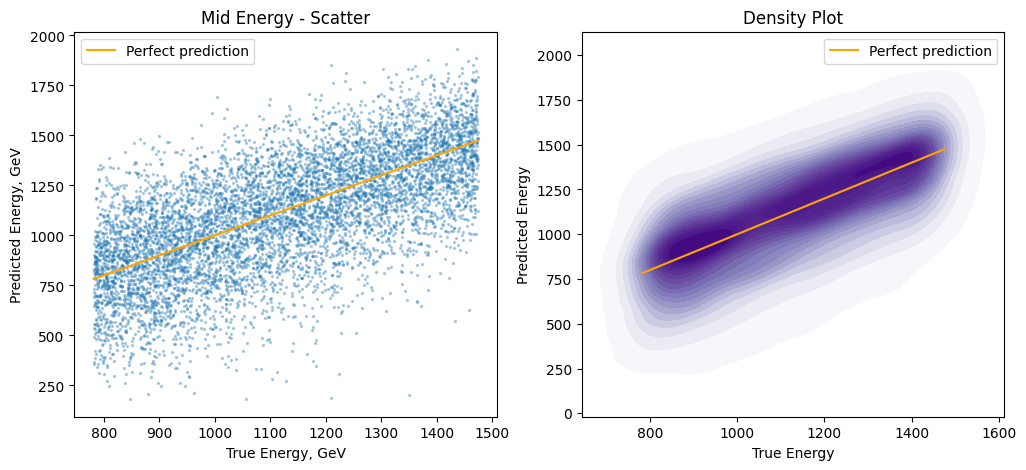

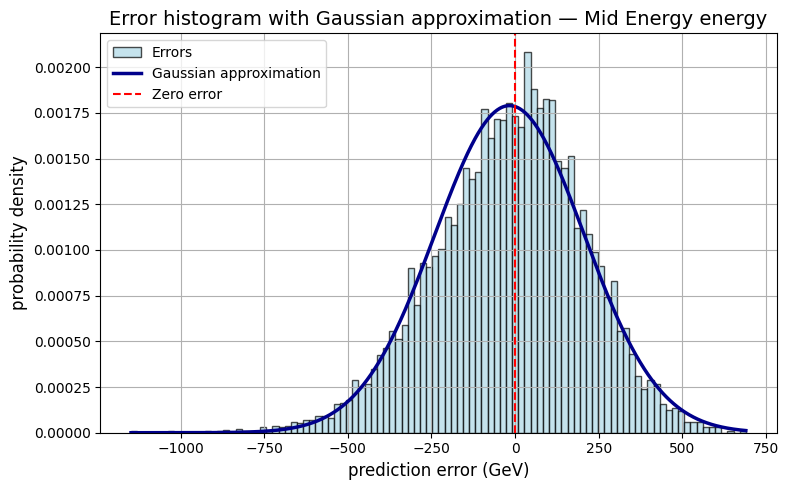

c:\Users\ПК\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(


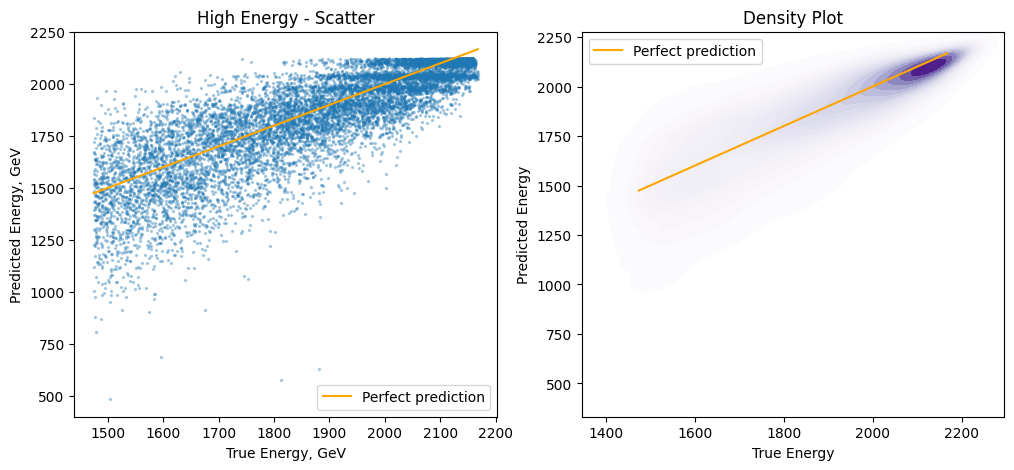

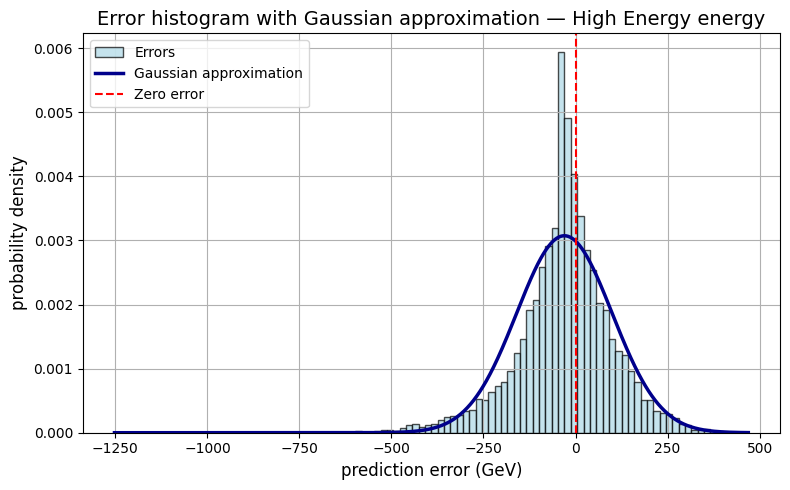

<Figure size 640x480 with 0 Axes>

In [32]:
# separation of energies by ranges (low, medium, high)

low_mask = y_true < d1
mid_mask = (y_true >= d1) & (y_true <= d2)
high_mask = y_true > d2

energy_ranges = {
    'Low Energy': low_mask,
    'Mid Energy': mid_mask,
    'High Energy': high_mask
}

for title, mask in energy_ranges.items():
    y_t = y_true[mask]
    y_p = y_pred[mask]
    errors = y_p - y_t

    plt.figure(figsize=(12, 5))

    # Scatter Plot
    plt.subplot(1, 2, 1)
    plt.scatter(y_t, y_p, s=2, alpha=0.3)
    plt.plot([y_t.min(), y_t.max()], [y_t.min(), y_t.max()], color='orange', label='Perfect prediction')
    plt.xlabel("True Energy, GeV")
    plt.ylabel("Predicted Energy, GeV")
    plt.title(f"{title} - Scatter")
    plt.legend()

    # Density + Contour
    plt.subplot(1, 2, 2)
    sns.kdeplot(x=y_t, y=y_p, fill=True, cmap="Purples", levels=20, thresh=0.01, linewidths=2.5, linestyles='solid')
    plt.plot([y_t.min(), y_t.max()], [y_t.min(), y_t.max()], color='orange', label='Perfect prediction')
    plt.xlabel("True Energy")
    plt.ylabel("Predicted Energy")
    plt.title("Density Plot")
    plt.legend()

    # Histogram
    
    plot_error_hist(errors, title)
    

plt.tight_layout()
plt.show()

In [ ]:
errors = y_pred - y_true
errors_np = errors.numpy()

#Error hist with gaussian aprox

mu = np.mean(errors_np)     
sigma = np.std(errors_np)   


plt.figure(figsize=(10, 5))
count, bins, ignored = plt.hist(errors_np, bins=100, density=True, color='lightblue', edgecolor='black', alpha=0.7, label='Ошибки')


x = np.linspace(min(errors_np), max(errors_np), 1000)
gaussian_curve = norm.pdf(x, mu, sigma)
plt.plot(x, gaussian_curve, color='darkblue', linewidth=2.5, label='Gaussian approximation')

plt.axvline(0, color='red', linestyle='--', label='Zero error')
plt.title("Error histogram with Gaussian approximation", fontsize=14)
plt.xlabel("prediction error (GeV)", fontsize=12)
plt.ylabel("probability density", fontsize=12)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

AttributeError: 'numpy.ndarray' object has no attribute 'numpy'

c:\Users\ПК\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(


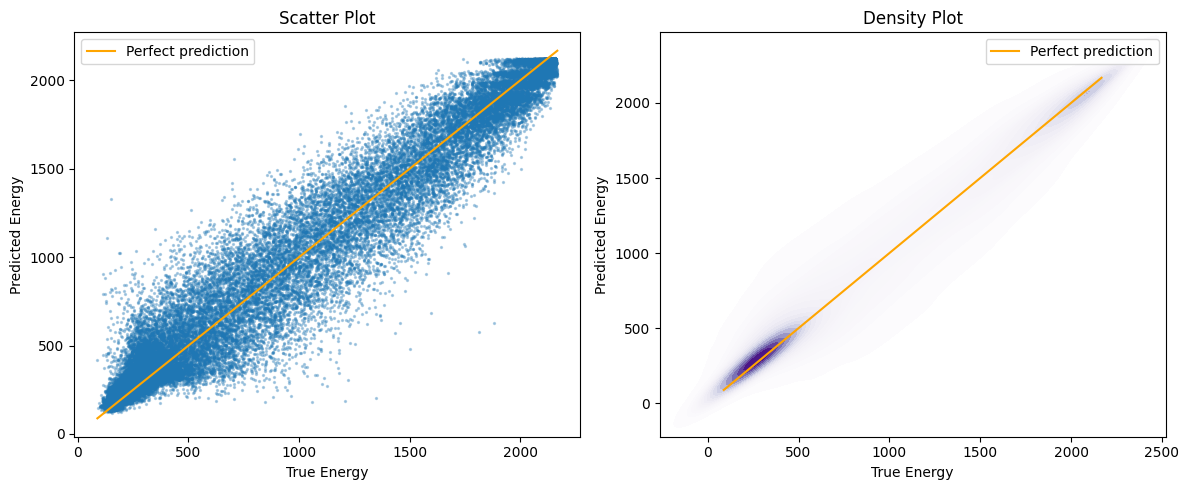

In [ ]:
import seaborn as sns

# full range of energy

y_true = y_test.squeeze().numpy()
y_pred = r(X_test).squeeze().detach().numpy()

plt.figure(figsize=(12, 5))

# Scatter Plot
plt.subplot(1, 2, 1)
plt.scatter(y_true, y_pred, s=2, alpha=0.3)
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], color='orange', label='Perfect prediction')
plt.xlabel("True Energy")
plt.ylabel("Predicted Energy")
plt.title("Scatter Plot")
plt.legend()

# Density + Contour
plt.subplot(1, 2, 2)
sns.kdeplot(x=y_true, y=y_pred, fill=True, cmap="Purples", levels=20, thresh=0.01, linewidths=2.5, linestyles='solid')
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], color='orange', label='Perfect prediction')
plt.xlabel("True Energy")
plt.ylabel("Predicted Energy")
plt.title("Density Plot")
plt.legend()

plt.tight_layout()
plt.show()

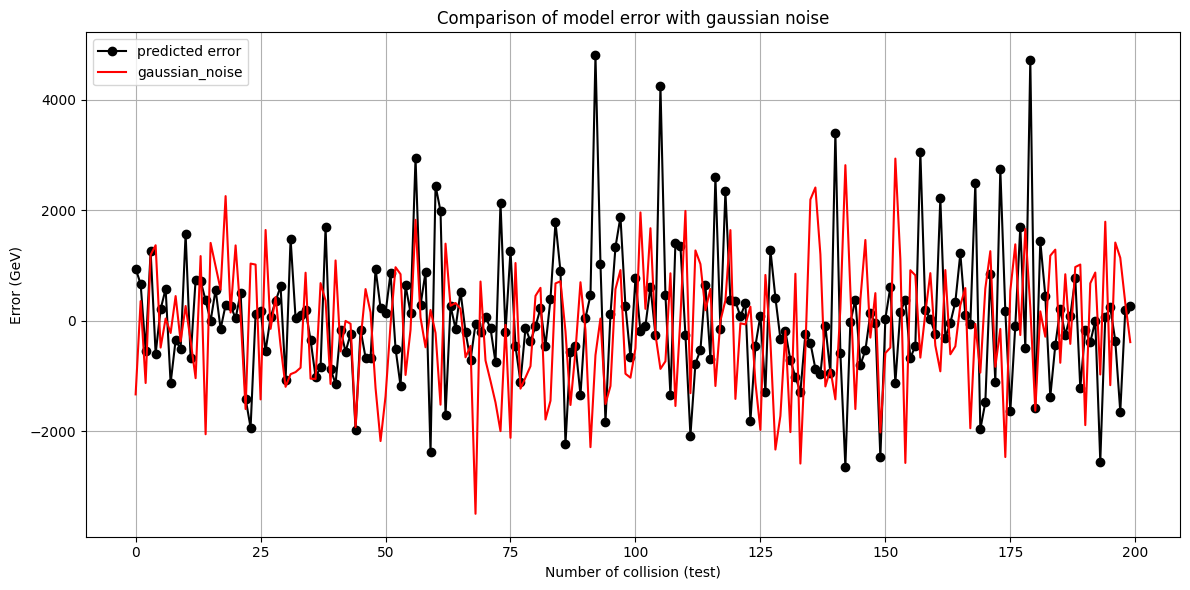

In [31]:
# prediction error
errors = (y_pred.squeeze() - torch.tensor(y_test, dtype = torch.float32)).numpy()
# standard deviation of errors
sigma = np.std(errors) 
gaussian_noise = np.random.normal(loc = 0, scale = sigma, size = len(errors))

plt.figure(figsize=(12, 6))
plt.plot(errors[:200], label = 'predicted error', color = 'black', marker = 'o')
plt.plot(gaussian_noise[:200], label = 'gaussian_noise', color = 'r')
plt.title('Comparison of model error with gaussian noise')
plt.xlabel('Number of collision (test)')
plt.ylabel('Error (GeV)')
plt.tight_layout()
plt.legend()
plt.grid(True)
plt.show()